# 3. BERT y comparación

**Responsable: Sara.**

El extractor BERT y su prueba con diez textos proceden del cuaderno original
de Mónica. Aquí se ha añadido selección de GPU, guardado compatible con el cuaderno
de Izan, medición del truncamiento, comprobaciones de la prueba y registro de la
configuración. El fine-tuning y el análisis final están pendientes.

Ejecutar desde la carpeta del proyecto. Para la extracción completa conviene usar
Colab con GPU (Entorno de ejecución → Cambiar tipo de entorno → T4 GPU): en CPU tarda horas.

## Preparación en Colab

Solo hace falta en Colab. La carpeta del proyecto debe estar en Google Drive con
`funciones.py`, `resultados/particiones.csv` y los dos Excel en `datos/`. Trabajar
desde Drive conserva `datos/cache/bert.joblib` cuando se cierra la sesión.
Una forma sencilla de prepararla es clonar el repositorio desde Colab en
`/content/drive/MyDrive` y subir después los Excel a `datos/`.
Fuera de Colab esta celda no hace nada.

In [15]:
import os
import sys

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    RUTA_PROYECTO = "/content/drive/MyDrive/proyecto-cordis"  # ajustar si está en otra carpeta
    os.chdir(RUTA_PROYECTO)
    if RUTA_PROYECTO not in sys.path:
        sys.path.insert(0, RUTA_PROYECTO)
print("Carpeta de trabajo:", os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Carpeta de trabajo: /content/drive/MyDrive/proyecto-cordis


In [16]:
import json
import platform
import time
from datetime import datetime

import numpy as np
import pandas as pd
import torch
import transformers
from IPython.display import display
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModel

from funciones import (
    RESULTADOS, CACHE, SEMILLA,
    guardar_representacion, cargar_representacion,
)

np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
print("Python:", platform.python_version(),
      "| torch:", torch.__version__,
      "| transformers:", transformers.__version__)

Python: 3.13.16 | torch: 2.14.1+cu130 | transformers: 5.22.1


In [17]:
from funciones import cargar_datos, preparar_datos, cargar_o_crear_particiones

projects, scivoc = cargar_datos()
df = preparar_datos(projects, scivoc)
conjuntos = cargar_o_crear_particiones(df)  # comprueba IDs, etiquetas y orden con el CSV común
df_train = conjuntos["train"]
df_val = conjuntos["val"]
df_test = conjuntos["test"]
print({nombre: len(parte) for nombre, parte in conjuntos.items()})

{'train': 19189, 'val': 9594, 'test': 3199}


## BERT congelado

Usamos el resumen original, sin el preprocesamiento de TF-IDF: BERT tiene su propio
tokenizador WordPiece y aprovecha mayúsculas, puntuación y palabras vacías como contexto
(el modelo *uncased* pasa a minúsculas internamente).

- **Modelo:** `bert-base-uncased` (12 capas, vectores de 768 dimensiones).
- **Congelado:** modo evaluación y sin gradientes. Sus pesos no cambian; solo se usa
  como extractor de características. Esto es lo que lo distingue del fine-tuning.
- **Un vector por documento:** media de los vectores de la última capa de todos los
  tokens reales. La máscara de atención excluye el padding. La media incluye `[CLS]` y
  `[SEP]`, como en la base inicial. Se prefiere la media al vector de `[CLS]` porque, sin
  fine-tuning, `[CLS]` no está entrenado para resumir el documento.
- **Textos largos:** se truncan a 512 tokens (el máximo de BERT, incluidos `[CLS]` y `[SEP]`).
  Más abajo se mide a cuántos resúmenes afecta.

Esta primera carga descarga los pesos si todavía no están en el ordenador.

In [18]:
modelo_nombre = "bert-base-uncased"
MAX_LEN = 512
dispositivo = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tokenizer = AutoTokenizer.from_pretrained(modelo_nombre)
modelo_bert = AutoModel.from_pretrained(modelo_nombre).to(dispositivo)
modelo_bert.requires_grad_(False)
modelo_bert.eval()
print("Dispositivo:", dispositivo,
      f"({torch.cuda.get_device_name(0)})" if dispositivo.type == "cuda" else "")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Dispositivo: cuda (Tesla T4)


In [19]:
textos = {
    nombre: parte["summary"].fillna("").astype(str).tolist()
    for nombre, parte in conjuntos.items()
}
for nombre, lista in textos.items():
    print(nombre, len(lista))

train 19189
val 9594
test 3199


## ¿Cuántos resúmenes superan los 512 tokens?

Se tokeniza sin truncar para medir la longitud real en tokens WordPiece, contando
`[CLS]` y `[SEP]`. Es normal que aparezca el aviso *Token indices sequence length is
longer than the specified maximum*: aquí solo medimos y no se pasa nada al modelo.

In [20]:
def longitudes_en_tokens(lista, tamano_lote=1000):
    longitudes = []
    for i in range(0, len(lista), tamano_lote):
        codificados = tokenizer(lista[i:i + tamano_lote], truncation=False)
        longitudes.extend(len(ids) for ids in codificados["input_ids"])
    return np.array(longitudes)

longitudes = {nombre: longitudes_en_tokens(lista) for nombre, lista in textos.items()}

filas = []
for nombre, L in longitudes.items():
    truncados = L > MAX_LEN
    filas.append(dict(
        conjunto=nombre,
        resumenes=len(L),
        tokens_media=round(L.mean(), 1),
        tokens_mediana=int(np.median(L)),
        tokens_p95=int(np.percentile(L, 95)),
        tokens_max=int(L.max()),
        truncados=int(truncados.sum()),
        porcentaje_truncados=round(100 * truncados.mean(), 2),
        tokens_perdidos_media=round(float((L[truncados] - MAX_LEN).mean()), 1) if truncados.any() else 0.0,
    ))
tabla_truncamiento = pd.DataFrame(filas)
display(tabla_truncamiento)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (625 > 512). Running this sequence through the model will result in indexing errors


,conjunto,resumenes,tokens_media,tokens_mediana,tokens_p95,tokens_max,truncados,porcentaje_truncados,tokens_perdidos_media
0,train,19189,354.5,366,422,838,15,0.08,105.2
1,val,9594,355.4,367,423,772,10,0.10,114.1
2,test,3199,354.6,366,423,538,3,0.09,14.7


**Interpretación (medido el 9/11/2026 en CPU, tabla anterior):** la mediana es de 366 tokens
y el 95 % de los resúmenes no llega a 425. Solo superan los 512 tokens 28 de los 31.982
resúmenes (15 en train, 10 en validación y 3 en test, un 0,09 %), y esos 28 conservan sus
primeros 512 tokens. El truncamiento es despreciable en este corpus: no compensa dividir los
textos largos en ventanas, y por el mismo motivo el fine-tuning también usa `max_length=512`.

In [21]:
def obtener_embeddings_bert(textos, batch_size=4, ordenar_por_longitud=True):
    """Devuelve una matriz (n, 768) en el MISMO orden que `textos`.

    Si ordenar_por_longitud=True, los lotes agrupan textos de longitud parecida para
    reducir el padding y acelerar la extracción. Cada vector se vuelve a escribir en
    su posición original, así que el orden de las filas no cambia.
    """
    n = len(textos)
    dimension = modelo_bert.config.hidden_size
    salida_total = np.zeros((n, dimension), dtype=np.float32)
    if n == 0:
        return salida_total
    orden = np.argsort([len(t) for t in textos], kind="stable") if ordenar_por_longitud else np.arange(n)

    for i in tqdm(range(0, n, batch_size), desc="Extrayendo BERT"):
        indices = orden[i:i + batch_size]
        entradas = tokenizer(
            [textos[j] for j in indices], padding=True, truncation=True,
            max_length=MAX_LEN, return_tensors="pt",
        )
        entradas = {k: v.to(dispositivo) for k, v in entradas.items()}
        with torch.no_grad():
            salida = modelo_bert(**entradas).last_hidden_state
            mascara = entradas["attention_mask"].unsqueeze(-1).to(salida.dtype)
            vector = (salida * mascara).sum(dim=1) / mascara.sum(dim=1).clamp(min=1)
        salida_total[indices] = vector.float().cpu().numpy()
    return salida_total

## Prueba con diez resúmenes

Antes de lanzar el corpus completo comprobamos:
1. que las dimensiones son (10, 768) y no hay valores no finitos;
2. que dos ejecuciones dan el mismo resultado;
3. que el padding no cambia el vector: procesar en lote o de uno en uno debe coincidir
   salvo ruido numérico (diferencias de 1e-4 o menos). Una diferencia grande indicaría
   que la máscara no está excluyendo el padding.

In [22]:
muestra = textos["train"][:10]
X_prueba_bert = obtener_embeddings_bert(muestra, batch_size=5)
X_repetida = obtener_embeddings_bert(muestra, batch_size=5)
X_uno_a_uno = obtener_embeddings_bert(muestra, batch_size=1)

print("Dimensiones de la prueba:", X_prueba_bert.shape)
print("Todos los valores son finitos:", bool(np.isfinite(X_prueba_bert).all()))
print("Diferencia máxima entre dos ejecuciones:", float(np.abs(X_prueba_bert - X_repetida).max()))
print("Diferencia máxima lote vs. uno a uno:", float(np.abs(X_prueba_bert - X_uno_a_uno).max()))

Extrayendo BERT:   0%|          | 0/2 [00:00<?, ?it/s]

Extrayendo BERT:   0%|          | 0/2 [00:00<?, ?it/s]

Extrayendo BERT:   0%|          | 0/10 [00:00<?, ?it/s]

Dimensiones de la prueba: (10, 768)
Todos los valores son finitos: True
Diferencia máxima entre dos ejecuciones: 0.0
Diferencia máxima lote vs. uno a uno: 7.152557373046875e-07


## Extracción completa

Cambiar `GENERAR_TODO` a `True` cuando se quiera ejecutar el corpus completo.
Los vectores se guardan fuera de GitHub en `datos/cache/bert.joblib` y se recargan
para comprobar que coinciden. Izan podrá cargarlos con `cargar_representacion("bert", conjuntos)`;
hay que pasarle el archivo por otro medio (Drive, por ejemplo).

La configuración realmente ejecutada (modelo, dispositivo, lote, tiempos, versiones y
truncamiento) se guarda en `resultados/bert_congelado_config.json`, que sí va a GitHub.

In [23]:
GENERAR_TODO = False

if GENERAR_TODO:
    batch_size = 32 if dispositivo.type == "cuda" else 4
    matrices_bert, minutos = {}, {}
    for nombre, lista in textos.items():
        inicio = time.time()
        matrices_bert[nombre] = obtener_embeddings_bert(lista, batch_size=batch_size)
        minutos[nombre] = round((time.time() - inicio) / 60, 2)
        assert matrices_bert[nombre].shape == (len(conjuntos[nombre]), modelo_bert.config.hidden_size)
        assert np.isfinite(matrices_bert[nombre]).all(), f"Valores no finitos en {nombre}"
        print(nombre, matrices_bert[nombre].shape, f"{minutos[nombre]} min")

    ruta = guardar_representacion("bert", matrices_bert, conjuntos)
    recargadas = cargar_representacion("bert", conjuntos)
    for nombre in matrices_bert:
        assert np.allclose(recargadas[nombre], matrices_bert[nombre]), nombre
    print("Vectores guardados y comprobados en:", ruta)

    registro = dict(
        fecha=datetime.now().isoformat(timespec="seconds"),
        modelo=modelo_nombre,
        congelado=True,
        pooling="media de la última capa sobre tokens con attention_mask=1 (incluye [CLS] y [SEP])",
        max_len=MAX_LEN,
        truncamiento="se conservan los primeros 512 tokens",
        texto="summary original, sin preprocesamiento",
        batch_size=batch_size,
        ordenado_por_longitud=True,
        dispositivo=torch.cuda.get_device_name(0) if dispositivo.type == "cuda" else "cpu",
        minutos=minutos,
        dimensiones={k: list(v.shape) for k, v in matrices_bert.items()},
        truncamiento_medido=tabla_truncamiento.to_dict(orient="records"),
        versiones=dict(python=platform.python_version(), torch=torch.__version__,
                       transformers=transformers.__version__),
        semilla=SEMILLA,
    )
    with open(RESULTADOS / "bert_congelado_config.json", "w", encoding="utf-8") as fichero:
        json.dump(registro, fichero, ensure_ascii=False, indent=2)
else:
    print("Extracción completa pendiente: activar GENERAR_TODO para ejecutarla.")

Extracción completa pendiente: activar GENERAR_TODO para ejecutarla.


## Fine-tuning de BERT

A diferencia de BERT congelado, aquí **se actualizan todos los pesos del Transformer** con
las etiquetas del problema. Se usa `AutoModelForSequenceClassification`: el mismo
`bert-base-uncased` más una capa lineal de clasificación sobre `[CLS]`, y todo se entrena junto.
Usar el mismo modelo base que en la versión congelada permite atribuir la diferencia
al hecho de adaptar los pesos, no a cambiar de modelo.

Decisiones:
- **Entrada:** el `summary` original, con las mismas particiones y `max_length=512`, porque
  solo se trunca el 0,09 % de los resúmenes. El padding se hace por lote (`DataCollatorWithPadding`).
- **Etiquetas:** los códigos EuroSciVoc se convierten en índices 0…K-1 con las clases de
  train, y el mapeo se guarda en `resultados/finetuning_mapeo_nivel{N}.json`.
- **Hiperparámetros:** dentro de los rangos habituales para BERT (Devlin et al., 2019:
  tasa de aprendizaje 2e-5 a 5e-5, lote 16 o 32, 2 a 4 épocas), con decaimiento de pesos 0,01
  y calentamiento del 10 % de los pasos. Se empieza con una sola configuración y se añaden
  más tasas solo si hay tiempo de GPU.
- **Selección con validación:** se evalúa al final de cada época, se guarda la época con
  mejor macro-F1 en validación y entre tasas se elige también por macro-F1 de validación.
  **El test no interviene.**
- **Solo con GPU:** en CPU tardaría días. Por eso `ENTRENAR_FT = False` por defecto y la
  celda se niega a entrenar sin GPU.
- `NIVEL = 2` es el proyecto básico. `NIVEL = 1` repite el experimento con las 6 raíces
  si el fine-tuning resulta la mejor configuración.

In [24]:
from pathlib import Path
from transformers import (
    AutoModelForSequenceClassification, DataCollatorWithPadding,
    Trainer, TrainingArguments, set_seed,
)
from funciones import evaluar

NIVEL = 2                    # 2 = proyecto básico (39 clases); 1 = repetición con 6 clases
ENTRENAR_FT = False          # True solo en Colab con GPU
TASAS_APRENDIZAJE = [2e-5]   # ampliar a [2e-5, 3e-5, 5e-5] si hay tiempo de GPU
EPOCAS = 3
BATCH = 16
MAX_LEN_FT = 512
CARPETA_MODELOS = Path("modelos")                  # pesos fuera de GitHub (.gitignore)
CARPETA_PREDICCIONES = RESULTADOS / "predicciones"
CARPETA_GRAFICAS = RESULTADOS / "graficas"
for carpeta in (CARPETA_MODELOS, CARPETA_PREDICCIONES, CARPETA_GRAFICAS):
    carpeta.mkdir(parents=True, exist_ok=True)

# Mapeo código EuroSciVoc -> índice consecutivo, aprendido con train
columna = f"label_nivel{NIVEL}"
clases = sorted(int(c) for c in conjuntos["train"][columna].unique())
for nombre in ("val", "test"):
    assert set(conjuntos[nombre][columna]) <= set(clases), f"Hay clases de {nombre} que no están en train"
codigo_a_indice = {c: i for i, c in enumerate(clases)}
indice_a_codigo = {i: c for c, i in codigo_a_indice.items()}
y_ft = {nombre: parte[columna].map(codigo_a_indice).to_numpy() for nombre, parte in conjuntos.items()}

with open(RESULTADOS / f"finetuning_mapeo_nivel{NIVEL}.json", "w", encoding="utf-8") as fichero:
    json.dump({"nivel": NIVEL, "indice_a_codigo": indice_a_codigo}, fichero, indent=2)
print(f"Nivel {NIVEL}: {len(clases)} clases")

Nivel 2: 39 clases


In [25]:
class ResumenesDataset(torch.utils.data.Dataset):
    """Resúmenes tokenizados sin padding; el padding lo añade el collator en cada lote."""
    def __init__(self, lista_textos, etiquetas):
        self.codificados = tokenizer(lista_textos, truncation=True, max_length=MAX_LEN_FT)
        self.etiquetas = etiquetas
    def __len__(self):
        return len(self.etiquetas)
    def __getitem__(self, i):
        item = {clave: valores[i] for clave, valores in self.codificados.items()}
        item["labels"] = int(self.etiquetas[i])
        return item

def metricas_ft(eval_pred):
    """Accuracy y macro-F1 sobre las K clases (las mismas que el resto del grupo)."""
    prediccion = np.argmax(eval_pred.predictions, axis=1)
    return evaluar(eval_pred.label_ids, prediccion, clases=list(range(len(clases))))

def guardar_metricas_sara(experimento, representacion, modelo, nivel, conjunto, metricas):
    """Mismo esquema que guardar_metricas, pero en resultados/metricas_sara.csv."""
    ruta = RESULTADOS / "metricas_sara.csv"
    fila = dict(experimento=experimento, representacion=representacion, modelo=modelo,
                nivel=nivel, conjunto=conjunto, **metricas)
    tabla = pd.read_csv(ruta) if ruta.exists() else pd.DataFrame(columns=list(fila))
    misma = (tabla["experimento"] == experimento) & (tabla["nivel"] == nivel) & (tabla["conjunto"] == conjunto)
    tabla = pd.concat([tabla.loc[~misma], pd.DataFrame([fila])], ignore_index=True)
    tabla.to_csv(ruta, index=False)
    return tabla

def guardar_predicciones(nombre_experimento, conjunto, y_pred_indices):
    """CSV con projectID, nivel, conjunto, etiqueta real y predicha (códigos EuroSciVoc)."""
    parte = conjuntos[conjunto]
    tabla = pd.DataFrame({
        "projectID": parte["projectID"].to_numpy(),
        "nivel": NIVEL,
        "conjunto": conjunto,
        "y_real": parte[columna].to_numpy(),
        "y_pred": [indice_a_codigo[int(i)] for i in y_pred_indices],
    })
    ruta = CARPETA_PREDICCIONES / f"{nombre_experimento}_{conjunto}.csv"
    tabla.to_csv(ruta, index=False)
    return ruta

### Entrenamiento y selección con validación

Para cada tasa de aprendizaje se entrena, se guarda la mejor época según macro-F1 en
validación, sus predicciones de validación, sus métricas y el historial de entrenamiento.
Los pesos del mejor modelo se guardan en `modelos/` (fuera de GitHub) para poder evaluar
el test más adelante sin volver a entrenar.

In [26]:
if ENTRENAR_FT:
    assert torch.cuda.is_available(), "El fine-tuning necesita GPU: ejecútalo en Colab con T4."
    datasets_ft = {nombre: ResumenesDataset(textos[nombre], y_ft[nombre]) for nombre in ("train", "val")}
    pasos_totales = int(np.ceil(len(datasets_ft["train"]) / BATCH)) * EPOCAS
    busqueda = []

    for lr in TASAS_APRENDIZAJE:
        set_seed(SEMILLA)
        nombre_exp = f"finetuning_bert_n{NIVEL}_lr{lr:g}"
        modelo_ft = AutoModelForSequenceClassification.from_pretrained(
            modelo_nombre, num_labels=len(clases),
            id2label={i: str(c) for i, c in indice_a_codigo.items()},
            label2id={str(c): i for i, c in indice_a_codigo.items()},
        )
        argumentos = TrainingArguments(
            output_dir=("/content/checkpoints/" if EN_COLAB else "checkpoints/") + nombre_exp,
            num_train_epochs=EPOCAS,
            learning_rate=lr,
            per_device_train_batch_size=BATCH,
            per_device_eval_batch_size=64,
            weight_decay=0.01,
            warmup_steps=int(0.1 * pasos_totales),
            eval_strategy="epoch",
            save_strategy="epoch",
            save_total_limit=1,
            load_best_model_at_end=True,
            metric_for_best_model="macro_f1",
            greater_is_better=True,
            logging_steps=50,
            fp16=True,
            seed=SEMILLA,
            report_to="none",
        )
        entrenador = Trainer(
            model=modelo_ft, args=argumentos,
            train_dataset=datasets_ft["train"], eval_dataset=datasets_ft["val"],
            data_collator=DataCollatorWithPadding(tokenizer),
            compute_metrics=metricas_ft,
        )
        inicio = time.time()
        entrenador.train()
        minutos = round((time.time() - inicio) / 60, 1)

        # Mejor época (ya cargada por load_best_model_at_end) evaluada en validación
        salida_val = entrenador.predict(datasets_ft["val"])
        pred_val = np.argmax(salida_val.predictions, axis=1)
        m_val = evaluar(conjuntos["val"][columna], [indice_a_codigo[int(i)] for i in pred_val], clases=clases)
        guardar_predicciones(nombre_exp, "val", pred_val)
        guardar_metricas_sara(nombre_exp, "texto original", "BERT fine-tuning", NIVEL, "val", m_val)

        entrenador.save_model(CARPETA_MODELOS / nombre_exp)
        tokenizer.save_pretrained(CARPETA_MODELOS / nombre_exp)
        with open(RESULTADOS / f"{nombre_exp}_historial.json", "w", encoding="utf-8") as fichero:
            json.dump(entrenador.state.log_history, fichero, indent=1)

        busqueda.append(dict(
            experimento=nombre_exp, nivel=NIVEL, learning_rate=lr, epocas=EPOCAS, batch=BATCH,
            max_len=MAX_LEN_FT, mejor_checkpoint=entrenador.state.best_model_checkpoint,
            val_accuracy=m_val["accuracy"], val_macro_f1=m_val["macro_f1"], minutos=minutos,
            gpu=torch.cuda.get_device_name(0), torch=torch.__version__,
            transformers=transformers.__version__, semilla=SEMILLA,
        ))
        print(nombre_exp, m_val, f"{minutos} min")
        del entrenador, modelo_ft
        torch.cuda.empty_cache()

    tabla_busqueda = pd.DataFrame(busqueda)
    ruta_busqueda = RESULTADOS / f"finetuning_busqueda_nivel{NIVEL}.csv"
    if ruta_busqueda.exists():  # conservar ejecuciones anteriores con otras tasas
        anteriores = pd.read_csv(ruta_busqueda)
        tabla_busqueda = pd.concat([anteriores[~anteriores["experimento"].isin(tabla_busqueda["experimento"])],
                                    tabla_busqueda], ignore_index=True)
    tabla_busqueda.to_csv(ruta_busqueda, index=False)
    display(tabla_busqueda)
else:
    print("Fine-tuning desactivado: poner ENTRENAR_FT = True en Colab con GPU.")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,1.874692,1.810476,0.515843,0.269677
2,1.579496,1.624523,0.562748,0.325763
3,1.367621,1.587098,0.572545,0.338073


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

/tmp/ipykernel_387/529351070.py:25: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  tabla = pd.concat([tabla.loc[~misma], pd.DataFrame([fila])], ignore_index=True)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

finetuning_bert_n2_lr2e-05 {'accuracy': 0.5725453408380238, 'macro_f1': 0.3380729772428865} 29.5 min


,experimento,nivel,learning_rate,epocas,batch,max_len,mejor_checkpoint,val_accuracy,val_macro_f1,minutos,gpu,torch,transformers,semilla
0,finetuning_bert_n2_lr2e-05,2,0.00002,3,16,512,/content/checkpoints/finetuning_bert_n2_lr2e-0...,0.572545,0.338073,29.5,Tesla T4,2.14.1+cu130,5.22.1,42


### Curvas de entrenamiento y validación

Se dibujan desde el historial guardado, así que se pueden regenerar sin volver a entrenar.
La pérdida de entrenamiento se registra cada 50 pasos; la de validación y el macro-F1, al
final de cada época. Si la pérdida de validación sube mientras la de entrenamiento baja,
hay sobreajuste, y la mejor época elegida debería ser anterior.

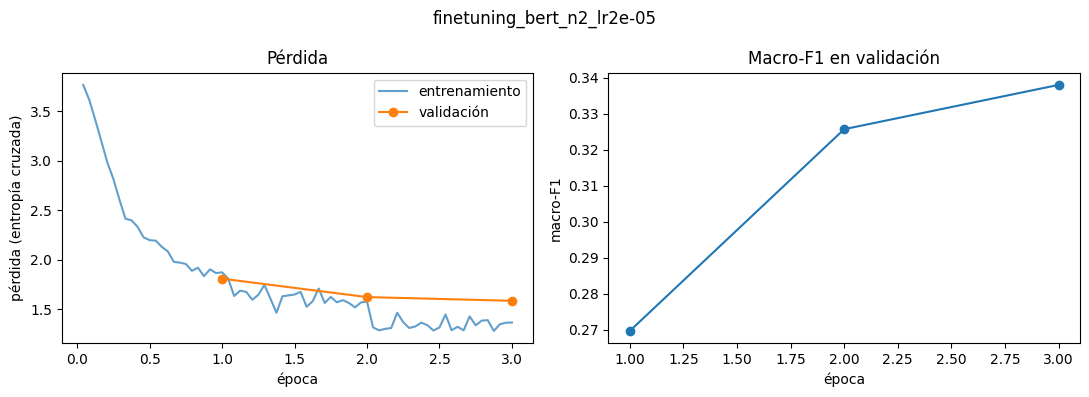

In [27]:
historiales = sorted(RESULTADOS.glob(f"finetuning_bert_n{NIVEL}_lr*_historial.json"))
if not historiales:
    print("Todavía no hay historiales de fine-tuning.")
else:
    import matplotlib.pyplot as plt
    for ruta in historiales:
        historial = json.load(open(ruta, encoding="utf-8"))
        entrenamiento = [(h["epoch"], h["loss"]) for h in historial if "loss" in h]
        evaluacion = [(h["epoch"], h["eval_loss"], h["eval_macro_f1"]) for h in historial if "eval_loss" in h]
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
        ax1.plot(*zip(*entrenamiento), label="entrenamiento", alpha=0.7)
        ax1.plot([e for e, _, _ in evaluacion], [l for _, l, _ in evaluacion], "o-", label="validación")
        ax1.set(xlabel="época", ylabel="pérdida (entropía cruzada)", title="Pérdida")
        ax1.legend()
        ax2.plot([e for e, _, _ in evaluacion], [f for _, _, f in evaluacion], "o-")
        ax2.set(xlabel="época", ylabel="macro-F1", title="Macro-F1 en validación")
        nombre_exp = ruta.stem.replace("_historial", "")
        fig.suptitle(nombre_exp)
        fig.tight_layout()
        fig.savefig(CARPETA_GRAFICAS / f"{nombre_exp}_curvas.png", dpi=150)
        plt.show()

### Evaluación final en test

**Ejecutar solo cuando el grupo haya cerrado todas las decisiones** (objetivo: 30 de
noviembre). Usa la configuración con mejor macro-F1 en validación, sin volver a entrenar.

In [28]:
EVALUAR_TEST = False

if EVALUAR_TEST:
    busqueda = pd.read_csv(RESULTADOS / f"finetuning_busqueda_nivel{NIVEL}.csv")
    mejor = busqueda.sort_values("val_macro_f1", ascending=False).iloc[0]
    print("Configuración elegida con validación:", mejor["experimento"])
    modelo_final = AutoModelForSequenceClassification.from_pretrained(CARPETA_MODELOS / mejor["experimento"])
    evaluador = Trainer(
        model=modelo_final,
        args=TrainingArguments(output_dir="checkpoints/test", per_device_eval_batch_size=64, report_to="none"),
        data_collator=DataCollatorWithPadding(tokenizer),
    )
    salida_test = evaluador.predict(ResumenesDataset(textos["test"], y_ft["test"]))
    pred_test = np.argmax(salida_test.predictions, axis=1)
    m_test = evaluar(conjuntos["test"][columna], [indice_a_codigo[int(i)] for i in pred_test], clases=clases)
    guardar_predicciones(mejor["experimento"], "test", pred_test)
    guardar_metricas_sara(mejor["experimento"], "texto original", "BERT fine-tuning", NIVEL, "test", m_test)
    print(m_test)
else:
    print("Evaluación en test pendiente: se hará al cerrar las decisiones.")

Evaluación en test pendiente: se hará al cerrar las decisiones.


## Comparación de resultados disponibles

Esta tabla se rellena al ejecutar los experimentos. Separar validación y test,
nivel 1 y nivel 2; no mezclar resultados iniciales con los definitivos.


In [29]:
metricas = pd.read_csv(RESULTADOS / "metricas.csv")
if metricas.empty:
    print("Todavía no hay métricas guardadas en esta copia del proyecto.")
else:
    display(metricas.sort_values(
        ["nivel", "conjunto", "macro_f1"], ascending=[True, True, False]
    ))


Todavía no hay métricas guardadas en esta copia del proyecto.


## Pendiente: evaluación final y nivel 1

Reunir resultados de Izan y del fine-tuning. Mostrar macro-F1, accuracy y métricas
por clase; incluir curvas de aprendizaje o validación y la matriz de confusión
completa de la mejor configuración.

Comparar el ranking de las tres representaciones en los niveles 1 y 2.
Si el fine-tuning es el mejor modelo global, incluir su repetición en nivel 1.


In [30]:
# PENDIENTE: tablas y figuras de la evaluación final.


## Pendiente: incertidumbre y errores

Establecer qué diferencia de rendimiento es suficientemente clara con nuestro
test y aplicar ese criterio a las conclusiones. Usar predicciones de los
mismos proyectos para comparar modelos.

Revisar ejemplos, clases pequeñas y confusiones entre categorías hermanas.
Se puede comprobar si la predicción era otra de las categorías válidas del
proyecto que descartamos al elegir una sola etiqueta.


In [31]:
# PENDIENTE: análisis de incertidumbre y ejemplos de errores.


## Para cerrar el trabajo

Integrar el texto que escriban Mónica e Izan en el README, incorporar todas las figuras
usadas en la discusión y revisar las conclusiones con el grupo.
Completar las contribuciones reales, las referencias y las diapositivas.
Comprobar que otra persona puede repetir el trabajo desde esta carpeta.
